# Does a neural network improve this surrogate?

**Chapter 10 comparison notebook.** Start with the [kernel notebook](10-resonant-surrogate.ipynb), then use this experiment to compare retrieval, linear interpolation, kernel ridge regression (KRR), and a small multilayer perceptron (MLP). Read the [chapter](../chapters/10-ai-metasurfaces.md), [lab](../labs/13-ai-metasurfaces.md), and [pilot guide](../chapters/10-pilot-guide.md).

The data come from a **synthetic analytical sheet**, not a full-wave solver or a manufactured structure. All amplitudes and frequencies are dimensionless. A notebook download runs independently after installing `requirements-labs.txt`; execution needs no external dataset, GPU, or network connection.

## 1. Declare the experiment before fitting

- Use the starter's 80 designs, 101 frequencies, seed 24, and 40/20/20 whole-design split.
- Select KRR from 12 candidates and the MLP from 6 candidates on validation complex RMSE. These are explicitly different search budgets, not an equal-cost benchmark.
- For neural selection use initialization 24 only. Freeze the selected architecture and regularization, then repeat with initializations 42 and 73. Report all three; never pick an initialization using test error.
- Fit the input scaler on the 40 training designs only. Targets are 101 real followed by 101 imaginary values; they need no relative rescaling because both describe the same bounded amplitude.
- Keep the training set fixed after selection: neither model is refitted using validation or test targets.
- Reveal test metrics only after every model is frozen. The random split mostly assesses interpolation in this one-dimensional family; coverage diagnostics below identify any boundary cases.
- Search the same 901 candidate coordinates for each continuous surrogate; retrieval returns one of the 40 actual training designs. Use the seed-24 MLP for that comparison, regardless of the test ranking.

The MLP uses tanh hidden units, linear outputs, L2 regularization, and L-BFGS. It has no internal validation split or early stopping. Optimizer warnings and iterations are reported. See the [MLPRegressor reference](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html) for the parameter definitions.

This is a reproducible teaching comparison on publicly available synthetic data, not a private blind benchmark. The code keeps test targets out of fitting and model selection. If you redesign the protocol after reading its published test results, use a new held-out experiment for any new accuracy claim.


In [1]:
import sys
import warnings
import time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import scipy
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown

SPLIT_SEED = 24
MLP_SEEDS = (24, 42, 73)
MLP_NAME = f"MLP (seed {MLP_SEEDS[0]})"
G_MIN, G_MAX, N_DESIGNS = 0.05, 0.95, 80
N_TRAIN, N_VALID = 40, 20
OMEGA_MIN, OMEGA_MAX, N_OMEGA = 0.8, 1.2, 101
OMEGA0_OFFSET, OMEGA0_SLOPE = 0.9, 0.2
GAMMA_OFFSET, GAMMA_SLOPE = 0.025, 0.02
LENGTH_SCALES = (0.03, 0.06, 0.12, 0.24)
KRR_ALPHAS = (1e-8, 1e-6, 1e-4)
MLP_LAYERS = ((16,), (32,), (32, 32))
MLP_ALPHAS = (1e-4, 1e-2)
MLP_MAX_ITER, MLP_MAX_FUN, MLP_TOL = 2000, 60000, 1e-8
PHASE_AMPLITUDE_MIN = 0.1
G_TARGET, N_CANDIDATES = 0.623, 901

assert 1 < N_TRAIN and 0 < N_VALID and N_TRAIN + N_VALID < N_DESIGNS
assert G_MIN < G_MAX and G_MIN <= G_TARGET <= G_MAX
assert OMEGA_MIN < OMEGA_MAX and N_OMEGA > 2 and N_CANDIDATES > 2
assert 0 < PHASE_AMPLITUDE_MIN < 1
assert len(set(MLP_SEEDS)) >= 3
assert all(x > 0 for x in (*LENGTH_SCALES, *KRR_ALPHAS, *MLP_ALPHAS))
print(f"Python {sys.version.split()[0]}; NumPy {np.__version__}; Matplotlib {matplotlib.__version__}; scikit-learn {sklearn.__version__}; SciPy {scipy.__version__}")
print("Synthetic analytical evidence only. One BLAS thread during training for a modest CPU workload.")

def table(headers, rows):
    display(Markdown("| " + " | ".join(headers) + " |\n| " + " | ".join(["---"] * len(headers)) + " |\n" +
                     "\n".join("| " + " | ".join(map(str, row)) + " |" for row in rows)))


Python 3.12.1; NumPy 2.4.6; Matplotlib 3.11.1; scikit-learn 1.9.1; SciPy 1.18.1
Synthetic analytical evidence only. One BLAS thread during training for a modest CPU workload.


## 2. Reproduce the physical generator and split

With $e^{-i\omega t}$, equal surrounding media, and power-normalized ports,

$$\Delta=\Omega-(0.9+0.2g),\quad\gamma=0.025+0.02g,\quad r=-\frac{\gamma}{\gamma-i\Delta},\quad t=1+r.$$

Check lossless power balance, resonance, and the complete two-port matrix. For $S=\begin{pmatrix}r&t\\t&r\end{pmatrix}$, the off-diagonal condition $r^*t+t^*r=0$ is needed in addition to $|r|^2+|t|^2=1$ to establish unitarity. This is a check of the analytical generator, not a constraint automatically satisfied by a regression model.


In [2]:
def resonant_sheet(g, omega):
    g = np.atleast_1d(np.asarray(g, dtype=float))[:, None]
    omega = np.atleast_1d(np.asarray(omega, dtype=float))[None, :]
    gamma = GAMMA_OFFSET + GAMMA_SLOPE * g
    if np.any(gamma <= 0):
        raise ValueError("The linewidth must be positive")
    delta = omega - (OMEGA0_OFFSET + OMEGA0_SLOPE * g)
    r = -gamma / (gamma - 1j * delta)
    return r, 1 + r

omega = np.linspace(OMEGA_MIN, OMEGA_MAX, N_OMEGA)
g_all = np.linspace(G_MIN, G_MAX, N_DESIGNS)
r_all, t_all = resonant_sheet(g_all, omega)
balance = np.abs(r_all)**2 + np.abs(t_all)**2 - 1
cross = np.conj(r_all) * t_all + np.conj(t_all) * r_all
assert np.max(np.abs(balance)) < 1e-12 and np.max(np.abs(cross)) < 1e-12
g_check = (G_MIN + G_MAX) / 2
r0, t0 = resonant_sheet(g_check, OMEGA0_OFFSET + OMEGA0_SLOPE*g_check)
assert np.allclose(r0, -1) and np.allclose(t0, 0)

ids = np.random.default_rng(SPLIT_SEED).permutation(N_DESIGNS)
train_ids = np.sort(ids[:N_TRAIN])
valid_ids = np.sort(ids[N_TRAIN:N_TRAIN + N_VALID])
test_ids = np.sort(ids[N_TRAIN + N_VALID:])
assert len(set(train_ids) & set(valid_ids)) == 0
assert len(set(train_ids) & set(test_ids)) == 0
assert len(set(valid_ids) & set(test_ids)) == 0
assert set(np.r_[train_ids, valid_ids, test_ids]) == set(range(N_DESIGNS))
g_train, y_train = g_all[train_ids], t_all[train_ids]
g_valid, y_valid = g_all[valid_ids], t_all[valid_ids]

print(f"Maximum generator balance residual: {np.max(np.abs(balance)):.3e}")
print(f"Maximum off-diagonal unitarity residual: {np.max(np.abs(cross)):.3e}")
for name, selection in [("Train", train_ids), ("Validation", valid_ids), ("Test", test_ids)]:
    outside = np.sum((g_all[selection] < g_train.min()) | (g_all[selection] > g_train.max()))
    print(f"{name}: IDs={selection.tolist()}; outside training-coordinate range={outside}")


Maximum generator balance residual: 5.551e-16
Maximum off-diagonal unitarity residual: 3.628e-16
Train: IDs=[0, 6, 7, 8, 11, 17, 22, 23, 25, 29, 31, 32, 33, 35, 36, 37, 38, 41, 42, 45, 49, 52, 53, 54, 56, 57, 58, 59, 61, 62, 63, 65, 66, 67, 68, 73, 75, 76, 77, 78]; outside training-coordinate range=0
Validation: IDs=[1, 2, 4, 10, 13, 16, 20, 21, 30, 34, 40, 43, 44, 46, 48, 50, 51, 69, 74, 79]; outside training-coordinate range=1
Test: IDs=[3, 5, 9, 12, 14, 15, 18, 19, 24, 26, 27, 28, 39, 47, 55, 60, 64, 70, 71, 72]; outside training-coordinate range=0


## 3. Retrieval, interpolation, and kernel regression

Retrieval chooses the nearest training coordinate. Linear interpolation brackets the query between training coordinates and blends their **complex amplitudes**, not wrapped phases. Outside the training range it clips to the closest endpoint; the coverage count above makes that limitation visible. It has no fitted hyperparameters.

KRR solves the same complex linear system as the starter. All candidate validation scores are retained. No result in this cell accesses test targets.


In [3]:
def complex_rmse(prediction, reference):
    return float(np.sqrt(np.mean(np.abs(prediction-reference)**2)))

def nearest_predict(g):
    nearest = np.argmin(np.abs(np.atleast_1d(g)[:, None]-g_train[None, :]), axis=1)
    return y_train[nearest]

def linear_predict(g):
    g = np.clip(np.atleast_1d(g), g_train[0], g_train[-1])
    right = np.clip(np.searchsorted(g_train, g, side="right"), 1, len(g_train)-1)
    left = right - 1
    fraction = ((g-g_train[left])/(g_train[right]-g_train[left]))[:, None]
    return (1-fraction)*y_train[left] + fraction*y_train[right]

def kernel(a, b, length):
    return np.exp(-0.5*((np.atleast_1d(a)[:, None]-np.atleast_1d(b)[None, :])/length)**2)

krr_trials = []
with threadpool_limits(limits=1):
    for length in LENGTH_SCALES:
        for alpha in KRR_ALPHAS:
            weights = np.linalg.solve(kernel(g_train, g_train, length)+alpha*np.eye(N_TRAIN), y_train)
            score = complex_rmse(kernel(g_valid, g_train, length) @ weights, y_valid)
            krr_trials.append((score, length, alpha, weights))
krr_score, best_length, best_alpha, krr_weights = min(krr_trials, key=lambda row: row[0])

def krr_predict(g):
    return kernel(g, g_train, best_length) @ krr_weights

table(["KRR length", "KRR alpha", "Validation complex RMSE"],
      [(length, f"{alpha:g}", f"{score:.6g}") for score, length, alpha, _ in krr_trials])
print(f"Selected KRR: length={best_length}, alpha={best_alpha:g}; validation RMSE={krr_score:.6g}")
assert np.allclose(linear_predict(g_train), y_train)


| KRR length | KRR alpha | Validation complex RMSE |
| --- | --- | --- |
| 0.03 | 1e-08 | 0.0283287 |
| 0.03 | 1e-06 | 0.028342 |
| 0.03 | 0.0001 | 0.028762 |
| 0.06 | 1e-08 | 0.00223332 |
| 0.06 | 1e-06 | 0.00286934 |
| 0.06 | 0.0001 | 0.00655375 |
| 0.12 | 1e-08 | 0.000643005 |
| 0.12 | 1e-06 | 0.00087218 |
| 0.12 | 0.0001 | 0.00205662 |
| 0.24 | 1e-08 | 0.00475058 |
| 0.24 | 1e-06 | 0.00668388 |
| 0.24 | 0.0001 | 0.012368 |

Selected KRR: length=0.12, alpha=1e-08; validation RMSE=0.000643005


## 4. Train a small neural surrogate

For one hidden layer, $\mathbf h=\tanh(W_1\widetilde g+\mathbf b_1)$ and $\widehat{\mathbf y}=W_2\mathbf h+\mathbf b_2$. The real output vector packs $[\operatorname{Re}t_1,\ldots,\operatorname{Re}t_M,\operatorname{Im}t_1,\ldots,\operatorname{Im}t_M]$.

The mean squared error averaged over these $2M$ coordinates is half the mean complex squared error averaged over $M$ frequencies. This constant factor preserves unregularized model rankings but should be remembered when interpreting the optimizer's loss and regularization. We select every model with **the same complex RMSE**, calculated after unpacking outputs.

Input scaling is fitted once using training inputs. The hidden weights change during training, but the physical design coordinate remains the input. L-BFGS is used because the dataset is small. Convergence warnings remain visible and a capped run must not be described as converged.


In [4]:
def pack(y):
    return np.concatenate([y.real, y.imag], axis=1)

def unpack(y):
    return y[:, :N_OMEGA] + 1j*y[:, N_OMEGA:]

assert np.allclose(unpack(pack(y_train)), y_train)
scaler = StandardScaler().fit(g_train[:, None])
x_train = scaler.transform(g_train[:, None])
x_valid = scaler.transform(g_valid[:, None])
assert np.allclose(scaler.mean_, np.mean(g_train))

def fit_mlp(layers, alpha, seed):
    model = MLPRegressor(hidden_layer_sizes=layers, activation="tanh", solver="lbfgs",
                         alpha=alpha, random_state=seed, max_iter=MLP_MAX_ITER,
                         max_fun=MLP_MAX_FUN, tol=MLP_TOL, early_stopping=False)
    start = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=1):
        warnings.simplefilter("always")
        model.fit(x_train, pack(y_train))
    messages = [f"{w.category.__name__}: {w.message}" for w in caught]
    return model, messages, time.perf_counter()-start

mlp_trials = []
for layers in MLP_LAYERS:
    for alpha in MLP_ALPHAS:
        model, messages, seconds = fit_mlp(layers, alpha, MLP_SEEDS[0])
        score = complex_rmse(unpack(model.predict(x_valid)), y_valid)
        mlp_trials.append(dict(layers=layers, alpha=alpha, score=score, model=model,
                               warnings=messages, seconds=seconds))
        for message in messages:
            print(f"layers={layers}, alpha={alpha}: {message}")
chosen = min(mlp_trials, key=lambda row: row["score"])
table(["Hidden layers", "L2 alpha", "Validation complex RMSE", "Iterations", "Warnings"],
      [(row["layers"], row["alpha"], f'{row["score"]:.6g}', row["model"].n_iter_, len(row["warnings"]))
       for row in mlp_trials])

# Architecture/alpha selection is now frozen. Repeat seeds without any new selection.
seed_models = {MLP_SEEDS[0]: chosen["model"]}
seed_warnings = {MLP_SEEDS[0]: chosen["warnings"]}
for seed in MLP_SEEDS[1:]:
    model, messages, _ = fit_mlp(chosen["layers"], chosen["alpha"], seed)
    seed_models[seed], seed_warnings[seed] = model, messages
    for message in messages:
        print(f"Repeat seed={seed}: {message}")

def mlp_predict(g, seed=MLP_SEEDS[0]):
    return unpack(seed_models[seed].predict(scaler.transform(np.atleast_1d(g)[:, None])))

n_parameters = sum(array.size for array in (*chosen["model"].coefs_, *chosen["model"].intercepts_))
print(f'Selected MLP: layers={chosen["layers"]}, alpha={chosen["alpha"]}; parameters={n_parameters}')
print(f'Primary seed {MLP_SEEDS[0]}; repeats {MLP_SEEDS[1:]}. Models frozen before test evaluation.')
print(f'Total MLP selection fits={len(mlp_trials)}, repeat fits={len(MLP_SEEDS)-1}.')


layers=(16,), alpha=0.01: ConvergenceWarning: lbfgs failed to converge after 35 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html


layers=(32,), alpha=0.01: ConvergenceWarning: lbfgs failed to converge after 53 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html


layers=(32, 32), alpha=0.01: ConvergenceWarning: lbfgs failed to converge after 79 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html


| Hidden layers | L2 alpha | Validation complex RMSE | Iterations | Warnings |
| --- | --- | --- | --- | --- |
| (16,) | 0.0001 | 0.0221315 | 439 | 0 |
| (16,) | 0.01 | 0.102208 | 35 | 1 |
| (32,) | 0.0001 | 0.0146041 | 582 | 0 |
| (32,) | 0.01 | 0.102718 | 53 | 1 |
| (32, 32) | 0.0001 | 0.0148536 | 601 | 0 |
| (32, 32) | 0.01 | 0.0836822 | 79 | 1 |

Selected MLP: layers=(32,), alpha=0.0001; parameters=6730
Primary seed 24; repeats (42, 73). Models frozen before test evaluation.
Total MLP selection fits=6, repeat fits=2.


## 5. Reveal the held-out comparison

All model choices are fixed. Report complex RMSE, transmission-power MAE (an absolute power fraction), amplitude MAE, worst pointwise complex error, and circular phase MAE where **both** amplitudes exceed 0.1. Also report the excluded fraction. Thresholding phase never excuses poor amplitude prediction.

For this sheet only, reconstruct $\widehat r=\widehat t-1$ and report $\max|\,|\widehat r|^2+|\widehat t|^2-1|$. A low residual does not mean the right spectrum: retrieval can conserve power while retrieving the wrong resonance. An interpolated complex amplitude may violate losslessness even though the endpoint spectra are lossless.


In [5]:
def metrics(prediction, reference):
    assert prediction.shape == reference.shape and np.isfinite(prediction).all()
    valid_phase = (np.abs(prediction) > PHASE_AMPLITUDE_MIN) & (np.abs(reference) > PHASE_AMPLITUDE_MIN)
    circular_error = np.abs(np.angle(prediction*np.conj(reference)))
    return dict(rmse=complex_rmse(prediction, reference),
                power_mae=float(np.mean(np.abs(np.abs(prediction)**2-np.abs(reference)**2))),
                amplitude_mae=float(np.mean(np.abs(np.abs(prediction)-np.abs(reference)))),
                max_complex_error=float(np.max(np.abs(prediction-reference))),
                phase_mae_deg=float(np.rad2deg(np.mean(circular_error[valid_phase]))) if valid_phase.any() else np.nan,
                excluded_pct=float(100*(1-valid_phase.mean())),
                balance_max=float(np.max(np.abs(np.abs(prediction-1)**2+np.abs(prediction)**2-1))))

predictors = {"Nearest": nearest_predict, "Linear": linear_predict, "KRR": krr_predict, MLP_NAME: mlp_predict}
g_test, y_test = g_all[test_ids], t_all[test_ids]
test_predictions = {name: predict(g_test) for name, predict in predictors.items()}
test_metrics = {name: metrics(pred, y_test) for name, pred in test_predictions.items()}
table(["Method", "Complex RMSE", "Power MAE", "Amplitude MAE", "Worst complex error"],
      [(name, *[f'{m[key]:.6g}' for key in ("rmse", "power_mae", "amplitude_mae", "max_complex_error")])
       for name, m in test_metrics.items()])
table(["Method", "Phase MAE (degrees)", "Phase excluded (%)", "Max balance residual"],
      [(name, f'{m["phase_mae_deg"]:.5g}', f'{m["excluded_pct"]:.4g}', f'{m["balance_max"]:.6g}')
       for name, m in test_metrics.items()])

seed_metrics = {seed: metrics(mlp_predict(g_test, seed), y_test) for seed in MLP_SEEDS}
table(["MLP seed", "Test complex RMSE", "Iterations", "Warnings"],
      [(seed, f'{seed_metrics[seed]["rmse"]:.6g}', seed_models[seed].n_iter_, len(seed_warnings[seed])) for seed in MLP_SEEDS])
seed_rmse = np.array([seed_metrics[seed]["rmse"] for seed in MLP_SEEDS])
print(f"MLP test RMSE across initializations: mean={seed_rmse.mean():.6g}; sample standard deviation={seed_rmse.std(ddof=1):.6g}")
print("Three initializations describe training variability on ONE fixed dataset split, not a confidence interval or split-generalization study.")


| Method | Complex RMSE | Power MAE | Amplitude MAE | Worst complex error |
| --- | --- | --- | --- | --- |
| Nearest | 0.0413522 | 0.0163445 | 0.016156 | 0.248744 |
| Linear | 0.00800124 | 0.00257662 | 0.00221517 | 0.0616918 |
| KRR | 0.000353376 | 7.65072e-05 | 6.04331e-05 | 0.00460979 |
| MLP (seed 24) | 0.0164935 | 0.00764698 | 0.00606226 | 0.0888655 |

| Method | Phase MAE (degrees) | Phase excluded (%) | Max balance residual |
| --- | --- | --- | --- |
| Nearest | 1.3211 | 2.376 | 4.44089e-16 |
| Linear | 0.30631 | 1.832 | 0.11514 |
| KRR | 0.0056121 | 1.832 | 0.00913201 |
| MLP (seed 24) | 0.6482 | 1.931 | 0.123928 |

| MLP seed | Test complex RMSE | Iterations | Warnings |
| --- | --- | --- | --- |
| 24 | 0.0164935 | 582 | 0 |
| 42 | 0.0220738 | 427 | 0 |
| 73 | 0.0310112 | 236 | 0 |

MLP test RMSE across initializations: mean=0.0231928; sample standard deviation=0.00732324
Three initializations describe training variability on ONE fixed dataset split, not a confidence interval or split-generalization study.


## 6. Inspect where errors occur

The illustrated test geometry is fixed by its position in the sorted test IDs, not selected after seeing which model wins. The scatter plot shows every held-out geometry. The vertical axis uses a logarithmic scale; compare the numbers as well as the curves.


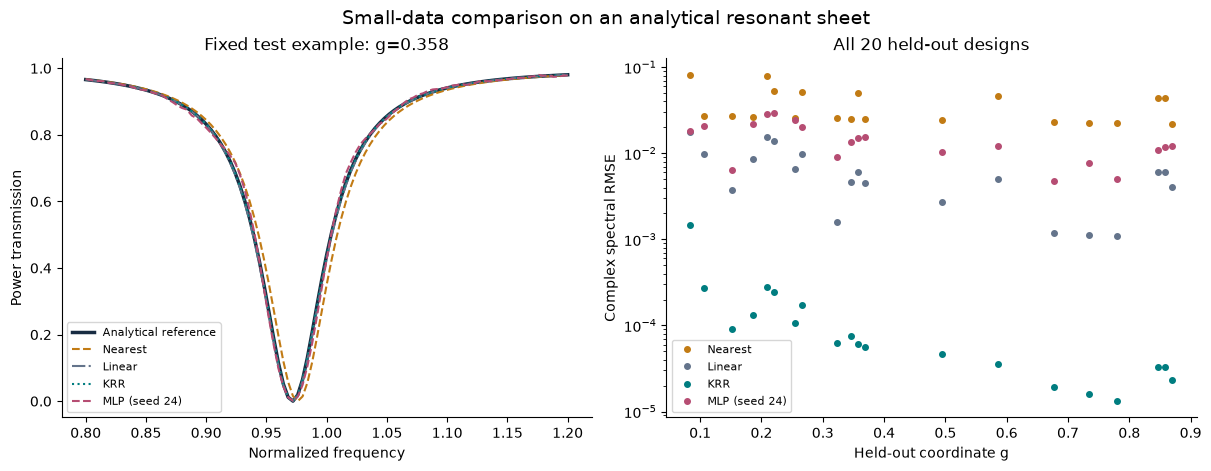

In [6]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
colors = {"Nearest": "#c27b14", "Linear": "#64748b", "KRR": "#007d80", MLP_NAME: "#b64d73"}
styles = {"Nearest": "--", "Linear": "-.", "KRR": ":", MLP_NAME: "--"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
example = len(test_ids)//2
axes[0].plot(omega, np.abs(y_test[example])**2, color="#182c42", lw=2.5, label="Analytical reference")
for name, pred in test_predictions.items():
    axes[0].plot(omega, np.abs(pred[example])**2, styles[name], color=colors[name], label=name)
    error = np.sqrt(np.mean(np.abs(pred-y_test)**2, axis=1))
    axes[1].semilogy(g_test, np.maximum(error, 1e-16), "o", ms=4, color=colors[name], label=name)
axes[0].set(xlabel="Normalized frequency", ylabel="Power transmission", title=f"Fixed test example: g={g_test[example]:.3f}")
axes[1].set(xlabel="Held-out coordinate g", ylabel="Complex spectral RMSE", title=f"All {len(test_ids)} held-out designs")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
fig.suptitle("Small-data comparison on an analytical resonant sheet", fontsize=14)
plt.show()


## 7. Compare inverse proposals with the exact generator

Create one feasible target at $g=0.623$. Each method sees its complex spectrum and searches the same bounded grid. The target coordinate is **not passed to the search**. For every selected coordinate, evaluate the analytical generator and compare predicted and verified target RMSE.

Retrieval has flat objective regions because it returns the same training spectrum for a range of queries. To avoid silently reporting a fictitious retrieved geometry, its candidate is the actual training coordinate with the smallest target mismatch. Its 40 distinct library candidates are a subset of the information used by the 901-grid search for the continuous surrogates. The grid resolution and candidate counts are printed explicitly.

The target happens to lie on the grid; a zero verified error is possible. This does not establish a continuous global optimum or performance on an unknown target family.


| Method | Selected g | Predicted target RMSE | Verified target RMSE |
| --- | --- | --- | --- |
| Nearest | 0.608228 | 0.0301948 | 0.0301948 |
| Linear | 0.623000 | 0.00270095 | 0 |
| KRR | 0.623000 | 3.2859e-05 | 0 |
| MLP (seed 24) | 0.625000 | 0.0114671 | 0.00408174 |

Target g=0.623; continuous-surrogate grid=901; spacing=0.001; retrieval candidates=40


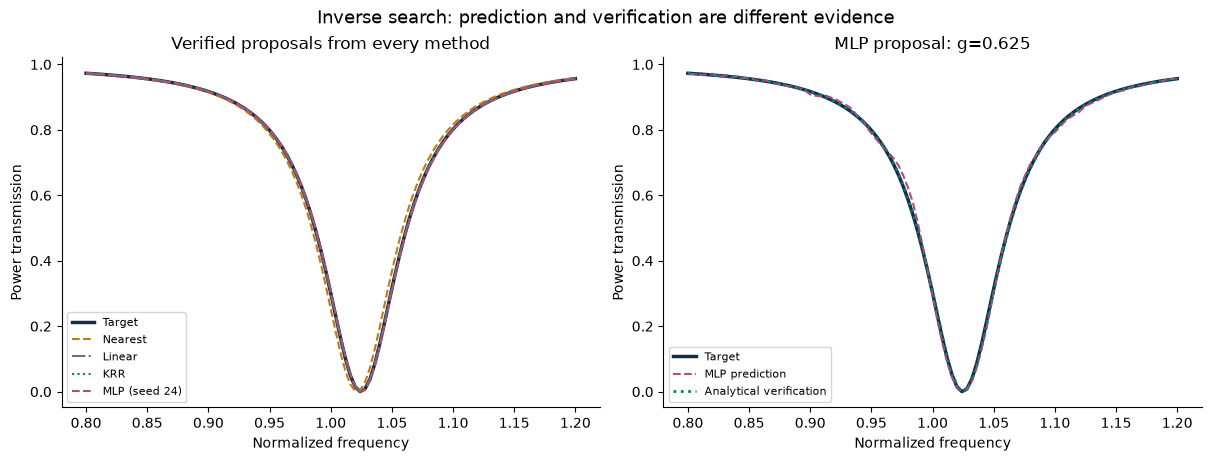

In [7]:
_, target = resonant_sheet(G_TARGET, omega)
g_candidates = np.linspace(G_MIN, G_MAX, N_CANDIDATES)
inverse_results = {}
for name, predict in predictors.items():
    candidates = g_train if name == "Nearest" else g_candidates
    spectra = predict(candidates)
    objectives = np.mean(np.abs(spectra-target)**2, axis=1)
    selected = int(np.argmin(objectives))
    g_selected = float(candidates[selected])
    predicted = spectra[selected:selected+1]
    r_verified, verified = resonant_sheet(g_selected, omega)
    assert G_MIN <= g_selected <= G_MAX and np.isfinite(objectives).all()
    assert np.max(np.abs(np.abs(r_verified)**2+np.abs(verified)**2-1)) < 1e-12
    inverse_results[name] = dict(g=g_selected, predicted=predicted, verified=verified,
                                 predicted_rmse=complex_rmse(predicted, target),
                                 verified_rmse=complex_rmse(verified, target))
table(["Method", "Selected g", "Predicted target RMSE", "Verified target RMSE"],
      [(name, f'{r["g"]:.6f}', f'{r["predicted_rmse"]:.6g}', f'{r["verified_rmse"]:.6g}')
       for name, r in inverse_results.items()])
print(f"Target g={G_TARGET}; continuous-surrogate grid={N_CANDIDATES}; spacing={g_candidates[1]-g_candidates[0]:.6g}; retrieval candidates={len(g_train)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].plot(omega, np.abs(target[0])**2, color="#182c42", lw=2.5, label="Target")
for name, result in inverse_results.items():
    axes[0].plot(omega, np.abs(result["verified"][0])**2, styles[name], color=colors[name], label=name)
mlp_result = inverse_results[MLP_NAME]
axes[1].plot(omega, np.abs(target[0])**2, color="#182c42", lw=2.5, label="Target")
axes[1].plot(omega, np.abs(mlp_result["predicted"][0])**2, "--", color="#b64d73", label="MLP prediction")
axes[1].plot(omega, np.abs(mlp_result["verified"][0])**2, ":", color="#007d80", lw=2, label="Analytical verification")
axes[0].set(title="Verified proposals from every method", xlabel="Normalized frequency", ylabel="Power transmission")
axes[1].set(title=f'MLP proposal: g={mlp_result["g"]:.3f}', xlabel="Normalized frequency", ylabel="Power transmission")
for ax in axes:
    ax.legend(fontsize=8)
fig.suptitle("Inverse search: prediction and verification are different evidence", fontsize=13)
plt.show()


## 8. Interpret, reproduce, and extend

Use the output tables to answer these questions before changing anything:

1. Which method has the smallest held-out complex RMSE? Does the answer change if you compare worst-case error or power balance instead?
2. Does the MLP improve on nearest retrieval and linear interpolation? Does it improve on KRR? A negative answer is a valid scientific result.
3. How large is initialization variability relative to the gap between methods? Would three initializations justify a general ranking across different datasets?
4. Which inverse proposal has the smallest **verified** target error? Why can this ranking differ from the ranking of predicted errors?
5. Explain why a retrieved spectrum can have negligible balance error and still match the target poorly.

For the report, retain split IDs, every validation candidate, selected settings, optimizer status, all three neural runs, both test-metric tables, and predicted-versus-verified inverse results. Report any warning without silently loosening the criterion.

**Extensions are new experiments.** Declare a new protocol before inspecting their tests: sweep the training count, withhold an entire design interval, vary linewidth, or add documented complex noise. Keep them separate from this reference comparison. Do not tune on the published test results and call the resulting test set untouched.

The next step toward a device study is [Stage B of the lab](../labs/13-ai-metasurfaces.md): a converged full-wave library with documented normalization and a geometry-level split. These analytical results do not demonstrate fabricated performance, full-wave accuracy, computational speedup, or universal superiority of any model.
